# Quantitative Proteomic Profiling of Extracellular Vesicle (EV) Uptake

This pipeline processes multiplexed isobaric labeling data (18-plex TMTpro coupled with metabolic SILAC pulse-chase) to quantify differential uptake of prostate carcinoma EV cargo (non-metastatic PC3 vs. metastatic PC3M) by recipient osteoblastic SAOS-2 cells.

## 0. Environment Configuration and Dependency Initialization

We import core scientific libraries for numerical processing, multivariate dimensionality reduction, statistical hypothesis testing, and supervised machine learning.

In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

## 1. Data Ingestion

We load the primary search export from Proteome Discoverer (`MEK_25_02_label_included.txt`). The raw tabular output includes peptide identifications, isotopic precursor annotations, spectral quality metrics, and continuous 18-plex TMT reporter ion intensities.

In [43]:
file_path = "MEK_25_02_label_included.txt"
df = pd.read_csv(file_path, sep="\t", low_memory=False)
print(f"Initial dataset shape: {df.shape[0]} peptide records, {df.shape[1]} metadata/intensity columns")
df.head(3)

Initial dataset shape: 88138 peptide records, 61 metadata/intensity columns


,Checked,Confidence,Annotated Sequence,Modifications,Contaminant,Number of Protein Groups,Number of Proteins,Number of PSMs,Master Protein Accessions,Positions in Master Proteins,...,q-Value by Search Engine Sequest HT,PEP by Search Engine Sequest HT,SVM Score by Search Engine Sequest HT,XCorr by Search Engine Sequest HT,PEP,q-Value,Channel Occupancy in Percent,Label,K label,R label
0,False,High,SDYLNTFEFMDK,1xTMTpro [N-Term]; 1xTMTpro [K12],False,1,1,2,O75874,O75874 [389-400],...,0.000029,5.638660e-06,1.29805,4.02,0.000006,0.000038,NaN,light,NaN,NaN
1,False,High,TLQALEFHTVPFQLLAR,1xTMTpro [N-Term],False,1,1,2,Q08380,Q08380 [377-393],...,0.000046,8.212470e-07,1.14519,2.94,0.000004,0.000038,NaN,light,NaN,NaN
2,False,High,QMADGGWGEDFESCEER,1xTMTpro [N-Term]; 1xCarbamidomethyl [C14],False,1,1,2,P48449,P48449 [623-639],...,0.000029,1.298870e-05,1.17893,5.13,0.000015,0.000038,NaN,light,NaN,NaN


| Column Name | Data Type / Example Values | Description & Interpretation |
| --- | --- | --- |
| **`Checked`** | Boolean (`False`) | Internal Proteome Discoverer user checkbox for manual verification. |
| **`Confidence`** | Categorical (`'High'`) | Overall identification confidence level calculated by Percolator. |
| **`Annotated Sequence`** | String (`'SDYLNTFEFMDK'`, etc.) | Amino acid sequence of the identified peptide. |
| **`Modifications`** | String (`1xTMTpro`, etc.) | Post-translational and chemical modifications identified on specific residues. |
| **`Contaminant`** | Boolean (`False`) | Flag identifying known laboratory contaminants (e.g., keratins, trypsin). |
| **`Number of Protein Groups`** | Integer (`0`, `1`) | Number of distinct protein groups to which the peptide sequence is assigned. |
| **`Number of Proteins`** | Integer (`1`, `2`, `3`, etc.) | Number of individual database entries (UniProt IDs) matching this peptide sequence. |
| **`Number of PSMs`** | Integer (`1`, `2`, `7`, etc.) | Peptide-Spectrum Matches: total number of times MS2 spectra matched this peptide. |
| **`Master Protein Accessions`** | String (`'O75874'`, etc.) | UniProt accession ID of the lead representative protein for the protein group. |
| **`Positions in Master Proteins`** | String (`'O75874 [389-400]'`) | Exact residue range coordinates of the peptide within the master protein sequence. |
| **`Modifications in Master Proteins`** | Mixed / Float (`NaN`) | Annotation of sequence-level modifications matched to the master sequence. |
| **`Number of Missed Cleavages`** | Integer (`0`, `1`, `2`) | Number of missed trypsin cleavage sites remaining within the sequence. |
| **`Theo MHplus in Da`** | Float ($\sim 2100\text{--}2700\text{ Da}$) | Theoretical monoisotopic mass of the protonated peptide precursor. |
| **`Abundance F13 XXX Sample`** *(Aggregated)* | Float (`nan`, `0.0`, etc.) | SPS-MS3 TMTpro reporter intensities across boost, empty, SAOS2 control, uptake experimental, and spike reference channels. |
| **`Quan Info`** | String (`'NoQuanValues'`, `NaN`) | Status flag indicating validity of quantitative MS3 measurement in PD. |
| **`Found in Sample F13 [Channel]`** | Categorical (`'High'`, `NaN`) | Discrete detection reliability indicator per channel. |
| **`Sequest HT Search Metrics`** *(Aggregated)* | Categorical / Float | Search engine diagnostic scores, $q$-values, PEP, SVM scores, and XCorr values from Sequest HT. |
| **`PEP`** & **`q-Value`** | Float ($\le 0.01$) | Global consensus posterior error probability and minimal FDR threshold. |
| **`Channel Occupancy in Percent`** | Float ($72.0\text{--}94.0\%$) | Proportion of the 18 TMT channels showing non-zero reporter signal. |
| **`Label`** | Categorical (`'light'`, `'heavy'`) | Metabolic SILAC isotope status (Heavy = vesicular cargo, Light = recipient cells). |
| **`K label`** & **`R label`** | Categorical | Isotope modification tags for deuterated Lysine-D8 and Arginine-10. |
| **`active_channels`** | Integer ($0\text{--}18$) | Custom calculated column counting TMT channels with abundance $> 0$. (Otherwise Nan) |
| **`Peptide Length`** | Integer ($7\text{--}30$) | Custom calculated column for length in amino acids after stripping modifications. |

## 2. Upstream Quality Control (MS1 and MS2 Levels)

Before applying quantitative normalization, we assess data across 4 parameters:
1. **Metabolic Label Ratio**: Proportion of Heavy (vesicular cargo) to Light (recipient SAOS-2 cellular background) peptides.
2. **Contaminant Annotation**: Verification that external contaminants (e.g., keratins, bovine trypsin) were filtered out during database searching.
3. **Peptide Uniqueness**: Frequency of peptide matches mapping uniquely to a single protein vs. shared across homologs.
4. **PSM False Discovery Rate**: Global $q$-value distribution to ensure high-confidence identification thresholds.

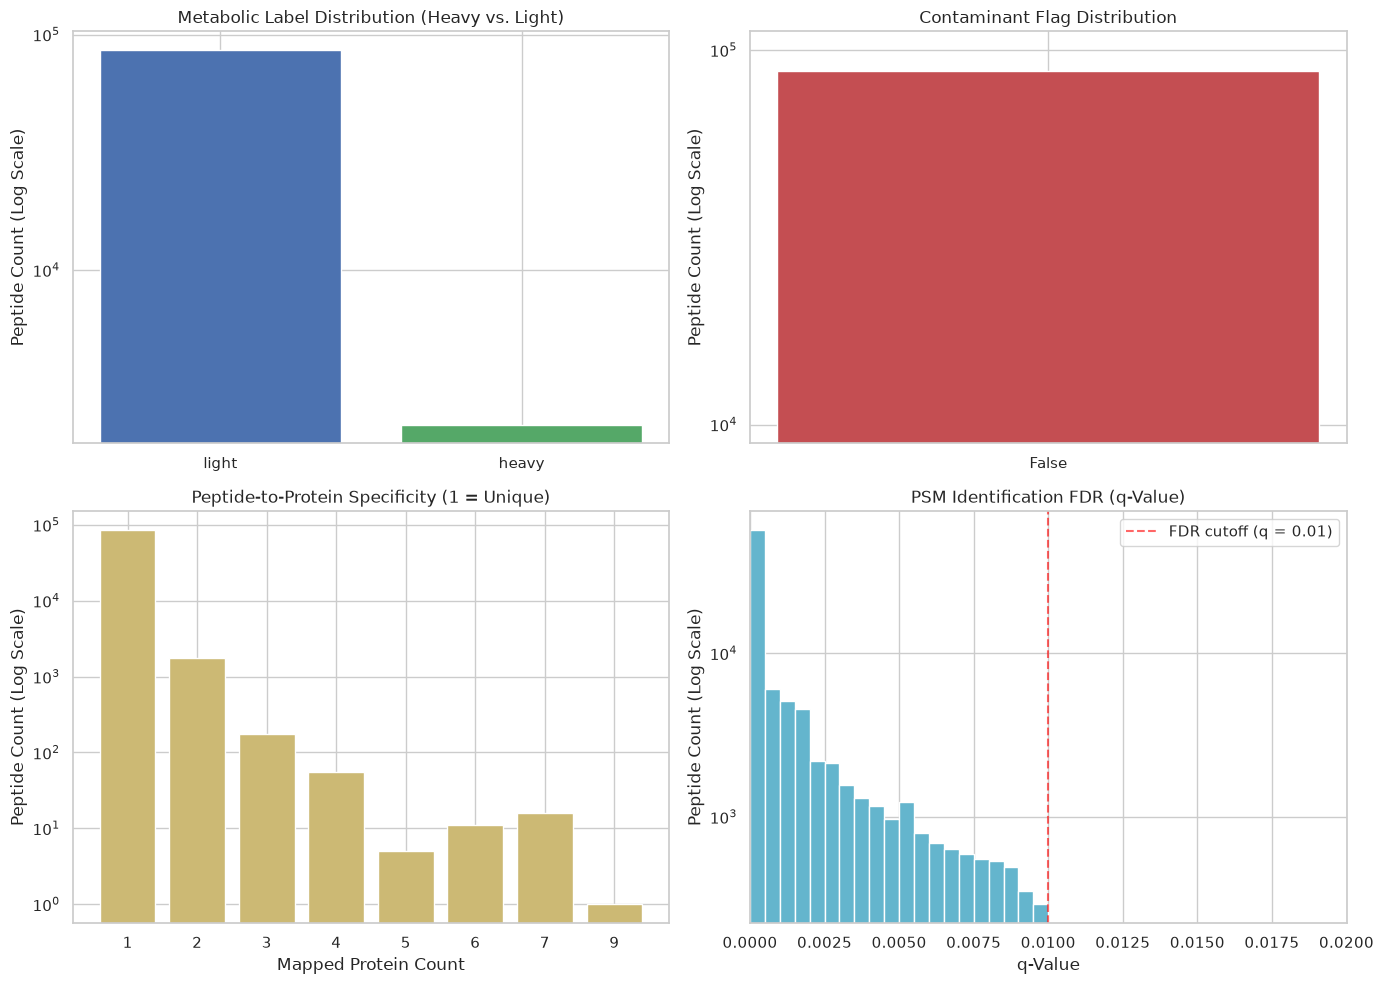

In [44]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Metabolic Label Distribution
label_counts = df["Label"].value_counts(dropna=False)
axes[0, 0].bar(label_counts.index.astype(str), label_counts.values, color=["#4C72B0", "#55A868"])
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Metabolic Label Distribution (Heavy vs. Light)")
axes[0, 0].set_ylabel("Peptide Count (Log Scale)")

# Panel 2: Contaminant Identification
contam_counts = df["Contaminant"].value_counts(dropna=False)
axes[0, 1].bar(contam_counts.index.astype(str), contam_counts.values, color=["#C44E52", "#8172B2"])
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Contaminant Flag Distribution")
axes[0, 1].set_ylabel("Peptide Count (Log Scale)")

# Panel 3: Peptide-to-Protein Mapping Ratio
prot_counts = df["Number of Proteins"].value_counts().sort_index().head(8)
axes[1, 0].bar(prot_counts.index.astype(str), prot_counts.values, color="#CCB974")
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Peptide-to-Protein Specificity (1 = Unique)")
axes[1, 0].set_xlabel("Mapped Protein Count")
axes[1, 0].set_ylabel("Peptide Count (Log Scale)")

# Panel 4: PSM Confidence Thresholds (q-value)
q_vals = pd.to_numeric(df["q-Value"], errors="coerce").dropna()
axes[1, 1].hist(q_vals, bins=100, color="#64B5CD", range=(0, 0.05), log=True)
axes[1, 1].axvline(0.01, color="red", linestyle="--", linewidth=1.5, alpha=0.6, label="FDR cutoff (q = 0.01)")
axes[1, 1].set_title("PSM Identification FDR (q-Value)")
axes[1, 1].set_xlabel("q-Value")
axes[1, 1].set_ylabel("Peptide Count (Log Scale)")
axes[1, 1].set_xlim(0, 0.02)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Baseline Filtering Summary

The table below delineates the input dataset structure at the peptide level prior to abundance filtering.

| QC Metric | Value / Criterion | Peptide Count ($n$) | Share of Pool ($\%$) | Pipeline Status |
| :--- | :--- | :--- | :--- | :--- |
| **Total Identifications** | Raw Proteome Discoverer output | **88,138** | **100.0%** | Raw input cohort |
| **PSM Spectral Confidence** | $q$-value $\le 0.01$ (FDR 1%) | 88,138 | 100.0% | Pre-filtered by search engine |
| **Contaminants** | `Contaminant == False` | 88,138 | 100.0% | Retained post-filtering |
| **Mapping Specificity** | `Number of Proteins == 1` | 86,106 | 97.7% | Strictly unique peptides |
| | `Number of Proteins > 1` | 2,032 | 2.3% | Shared / razor peptides |
| **Metabolic Origin** | `Label == 'light'` (recipient cells) | 85,929 | 97.5% | Background recipient proteome |
| | `Label == 'heavy'` (EV cargo) | 2,209 | 2.5% | Target vesicular proteome |

## 3. Enzymatic Cleavage and Peptide Length Profiling

To verify tryptic digestion efficiency and ensure analytical uniformity between heavy and light pools, we evaluate sequence length distributions.

Sequence length summary metrics:
Total peptides:         88138
Minimum length:         7 aa
Median length:          12.0 aa
Mean length:            13.13 aa
Maximum length:         30 aa


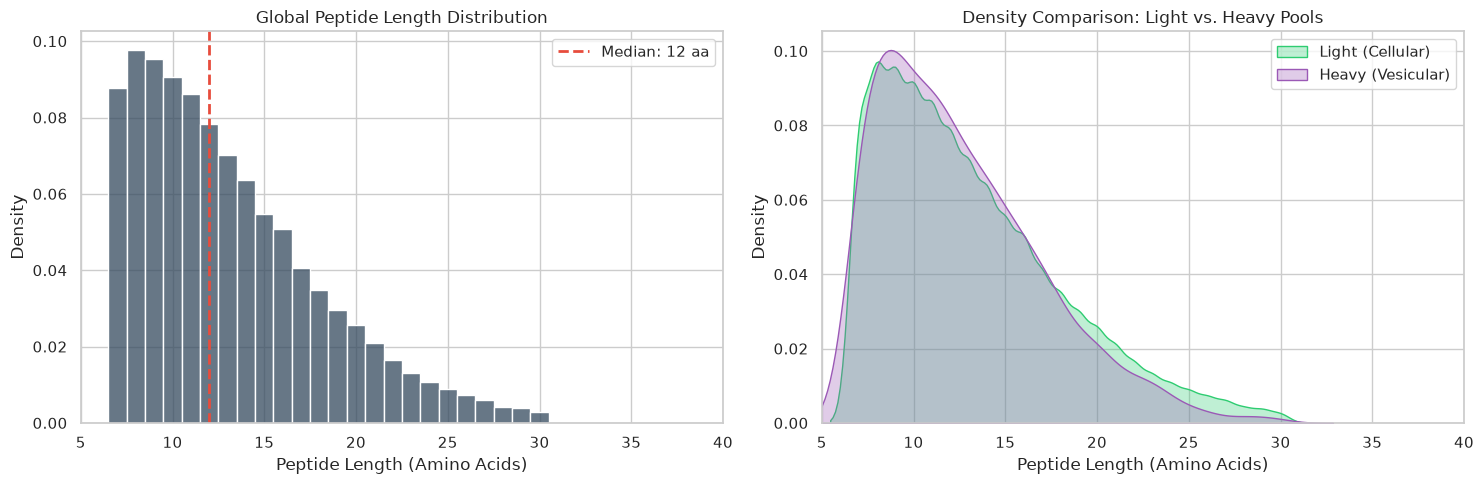

In [45]:
df["Peptide Length"] = df["Annotated Sequence"].apply(len)

stats_all = df["Peptide Length"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
print("=" * 55)
print("Sequence length summary metrics:")
print(f"Total peptides:         {int(stats_all['count'])}")
print(f"Minimum length:         {int(stats_all['min'])} aa")
print(f"Median length:          {stats_all['50%']:.1f} aa")
print(f"Mean length:            {stats_all['mean']:.2f} aa")
print(f"Maximum length:         {int(stats_all['max'])} aa")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bins = np.arange(df["Peptide Length"].min() - 0.5, min(df["Peptide Length"].max(), 40) + 1.5, 1)

sns.histplot(data=df, x="Peptide Length", bins=bins, color="#34495e", ax=axes[0], stat="density", discrete=True)
axes[0].axvline(df["Peptide Length"].median(), color="#e74c3c", linestyle="--", linewidth=2, label=f"Median: {df['Peptide Length'].median():.0f} aa")
axes[0].set_title("Global Peptide Length Distribution")
axes[0].set_xlabel("Peptide Length (Amino Acids)")
axes[0].set_ylabel("Density")
axes[0].set_xlim(5, 40)
axes[0].legend()

sns.kdeplot(data=df[df["Label"] == "light"], x="Peptide Length", color="#2ecc71", fill=True, alpha=0.3, label="Light (Cellular)", ax=axes[1], common_norm=False)
sns.kdeplot(data=df[df["Label"] == "heavy"], x="Peptide Length", color="#9b59b6", fill=True, alpha=0.3, label="Heavy (Vesicular)", ax=axes[1], common_norm=False)
axes[1].set_title("Density Comparison: Light vs. Heavy Pools")
axes[1].set_xlabel("Peptide Length (Amino Acids)")
axes[1].set_ylabel("Density")
axes[1].set_xlim(5, 40)
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. TMT Multiplex Reporter Occupancy Diagnostics

We next evaluate channel occupancy across the 18 TMT reporter channels. Peptides with zero intensity across all channels reflect records identified in MS2 but not selected or quantified at the MS3 level.

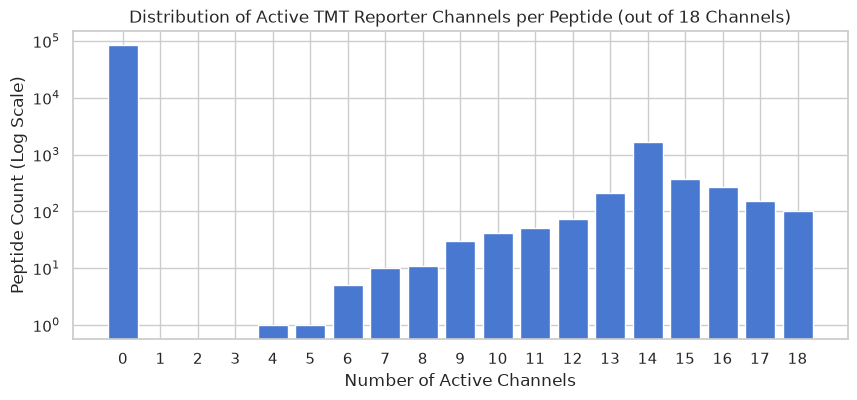

Channel occupancy summary by isotopic label:
       count  median      mean
Label                         
heavy   2209     0.0  6.625170
light  85929     0.0  0.324815


In [46]:
abundance_cols = [c for c in df.columns if c.startswith("Abundance F13")]
df[abundance_cols] = df[abundance_cols].apply(pd.to_numeric, errors="coerce")
df["active_channels"] = (df[abundance_cols] > 0).sum(axis=1)

plt.figure(figsize=(10, 4))
plt.hist(df["active_channels"], bins=range(20), align="left", rwidth=0.8, color="#4878D0", log=True)
plt.title("Distribution of Active TMT Reporter Channels per Peptide (out of 18 Channels)")
plt.xlabel("Number of Active Channels")
plt.ylabel("Peptide Count (Log Scale)")
plt.xticks(range(19))
plt.show()

print("Channel occupancy summary by isotopic label:")
print(df.groupby("Label")["active_channels"].agg(["count", "median", "mean"]))

## 5. Investigation of Unquantified Heavy Peptides (RTS Duty Cycle Analysis)

Within the target heavy subset ($n = 2,209$), roughly half contain zero reporter intensities across all channels. We inspect the `Quan Info` diagnostic column to determine whether this stems from real-time search (RTS) duty-cycle limits or post-acquisition spectral exclusion.

In [47]:
quan_breakdown = df[df["Label"] == "heavy"]["Quan Info"].value_counts(dropna=False)
print("Quantification status for Heavy peptides:")
print(quan_breakdown)

Quantification status for Heavy peptides:
Quan Info
NoQuanValues        1175
NaN                 1018
ExcludedByMethod      16
Name: count, dtype: int64


| Status Flag | Peptide Count ($n$) | Share of Heavy ($\%$) | Analytical Cause |
| :--- | :--- | :--- | :--- |
| **NaN (Passed)** | 1,018 | 46.1% | Valid SPS-MS3 scan passed all filtering criteria. |
| **NoQuanValues** | 1,175 | 53.2% | Precursor confirmed at MS2, but MS3 was not triggered (RTS duty cycle limitation). |
| **ExcludedByMethod** | 16 | 0.7% | MS3 scan acquired but rejected due to high co-isolation or low SPS match. |

Spectral exclusion due to poor scan quality accounts for only $0.7\%$ of heavy peptides. The primary attrition factor was instrument duty-cycle constraints during real-time triggering.

## 6. Quantifiable Heavy Peptide Cohort

We isolate the 1,018 quantifiable heavy peptides (`active_channels > 0`) and examine their channel occupancy across replicates.

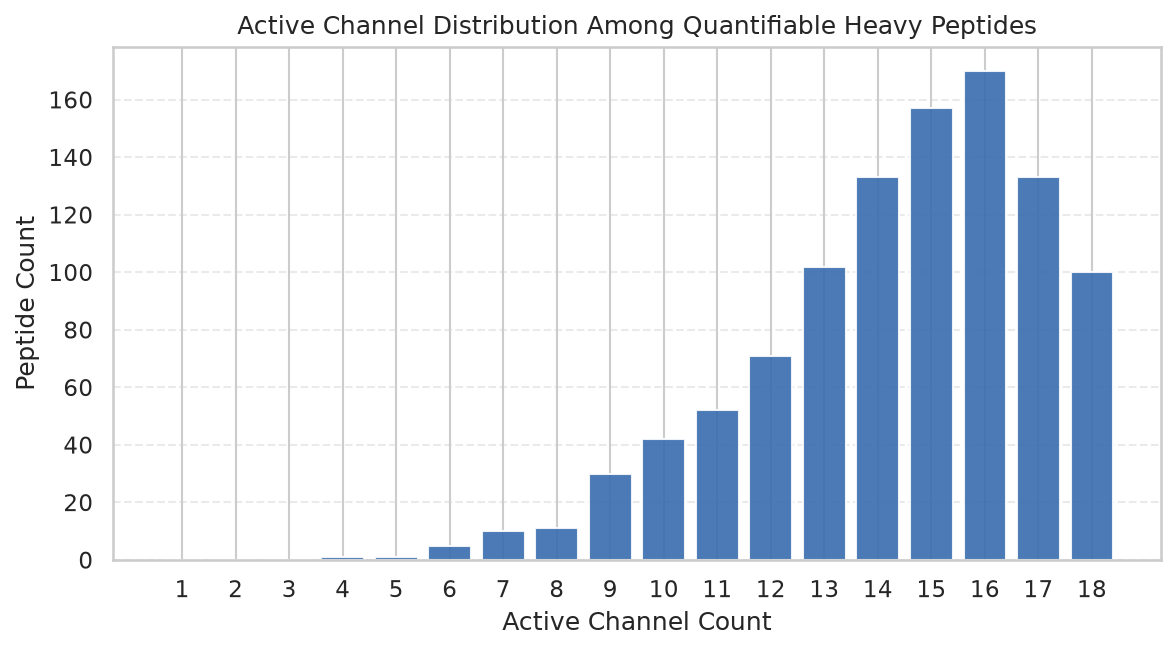

In [48]:
heavy_df = df[df["Label"] == "heavy"].copy()
mask_active = heavy_df["active_channels"] > 0

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.hist(heavy_df.loc[mask_active, "active_channels"], bins=range(1, 20), align="left", rwidth=0.8, color="#386cb0", alpha=0.9)
ax.set_title("Active Channel Distribution Among Quantifiable Heavy Peptides")
ax.set_xlabel("Active Channel Count")
ax.set_ylabel("Peptide Count")
ax.set_xticks(range(1, 19))
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 7. Experimental Design Mapping and Channel Annotation

We load experimental layout metadata from `TMT_pool.xlsx` and map the raw TMT reporter channels (`Abundance F13 ...`) to biological conditions.

Channels `127C` and `128N` were blank wells (negative controls). The remaining channels correspond to biological conditions:
- **SAOS-2 alone (Controls R1–R3)**: `128C`, `129N`, `129C` (baseline cellular background).
- **SAOS-2 + PC3 EV (Samples R1–R3)**: `130N`, `130C`, `131N` (non-metastatic cargo uptake).
- **SAOS-2 + PC3M EV (Samples R1–R4)**: `131C`, `132N`, `132C`, `135N` (metastatic cargo uptake).
- **Spike-in EV Cargo (Controls)**: `133N`, `133C` (PC3 spike), `134N`, `134C` (PC3M spike).

In [49]:
rename_channels = {
    "Abundance F13 126 Sample": "boost_PC3_EV",
    "Abundance F13 127N Sample": "boost_PC3M_EV",
    "Abundance F13 127C Sample": "empty_1",
    "Abundance F13 128N Sample": "empty_2",
    "Abundance F13 128C Sample": "SAOS2_ctrl_R1",
    "Abundance F13 129N Sample": "SAOS2_ctrl_R2",
    "Abundance F13 129C Sample": "SAOS2_ctrl_R3",
    "Abundance F13 130N Sample": "PC3_EV_R1",
    "Abundance F13 130C Sample": "PC3_EV_R2",
    "Abundance F13 131N Sample": "PC3_EV_R3",
    "Abundance F13 131C Sample": "PC3M_EV_R1",
    "Abundance F13 132N Sample": "PC3M_EV_R2",
    "Abundance F13 132C Sample": "PC3M_EV_R3",
    "Abundance F13 133N Sample": "spike_PC3_R1",
    "Abundance F13 133C Sample": "spike_PC3_R2",
    "Abundance F13 134N Sample": "spike_PC3M_R1",
    "Abundance F13 134C Sample": "spike_PC3M_R2",
    "Abundance F13 135N Sample": "PC3M_EV_R4",
}

meta_cols = [
    "Annotated Sequence",
    "Master Protein Accessions",
    "Positions in Master Proteins",
    "Number of Proteins",
    "Number of Protein Groups",
    "Number of PSMs",
    "q-Value",
    "Label",
    "Peptide Length",
    "active_channels",
]

df_renamed = df.rename(columns=rename_channels)
df_peptides_clean = df_renamed[
    (df_renamed["Label"] == "heavy") & (df_renamed["active_channels"] > 0)
][meta_cols + list(rename_channels.values())].copy()

print(f"Cleaned target peptide matrix: {df_peptides_clean.shape[0]} peptides, {df_peptides_clean.shape[1]} columns")
df_peptides_clean.head(3)

Cleaned target peptide matrix: 1018 peptides, 28 columns


,Annotated Sequence,Master Protein Accessions,Positions in Master Proteins,Number of Proteins,Number of Protein Groups,Number of PSMs,q-Value,Label,Peptide Length,active_channels,...,PC3_EV_R2,PC3_EV_R3,PC3M_EV_R1,PC3M_EV_R2,PC3M_EV_R3,spike_PC3_R1,spike_PC3_R2,spike_PC3M_R1,spike_PC3M_R2,PC3M_EV_R4
318,NNTVTPGGKPNK,P18077,P18077 [55-66],1,1,1,0.000038,heavy,12,15,...,5.2,4.8,5.8,8.4,9.2,103.1,71.8,87.7,99.7,4.4
415,GPPASSPAPAPK,Q15942,Q15942 [254-265],1,1,1,0.000038,heavy,12,17,...,7.8,8.0,5.8,8.5,11.3,37.5,39.1,49.7,44.2,8.1
638,GDVTAEEAAGASPAK,P49006,P49006 [11-25],1,1,1,0.000038,heavy,15,14,...,6.7,9.3,0.0,10.0,10.5,123.8,119.8,70.6,70.8,6.7


## 8. Protein Group Resolution and Shared Peptide Evaluation

All 1,018 peptides belong to a single protein group (`Number of Protein Groups == 1`). However, 73 peptides map to multiple closely related proteins within the group (`Number of Proteins > 1`).

Strict exclusion of these 73 shared peptides would completely discard 20 proteins, including canonical EV cytoskeletal markers (`ACTB`, `ACTC1`, `TUBA4A`, `VIM`) whose tryptic fragments are identical between isoforms. Therefore, we track both cohorts:
- **`df_proteins_strict`**: Derived exclusively from 945 strictly unique peptides (373 proteins).
- **`df_proteins_expanded`**: Derived from all 1,018 peptides (393 proteins).

In [50]:
df_shared_73 = df_peptides_clean[
    (df_peptides_clean["Number of Protein Groups"] == 1) & (df_peptides_clean["Number of Proteins"] != 1)
]

unique_prot_set = set(df_peptides_clean[df_peptides_clean["Number of Proteins"] == 1]["Master Protein Accessions"])
shared_prot_set = set(df_shared_73["Master Protein Accessions"])
lost_proteins = shared_prot_set - unique_prot_set

print(f"Proteins identified by strictly unique peptides: {len(unique_prot_set)}")
print(f"Proteins identified exclusively via shared peptides: {len(lost_proteins)}")
if lost_proteins:
    print("Excluded candidate examples:", *sorted(list(lost_proteins))[:8], sep=" ")

Proteins identified by strictly unique peptides: 373
Proteins identified exclusively via shared peptides: 20
Excluded candidate examples: O00571 O14493 O14818 P04908 P05388 P07910 P08670 P0C0S8


## 9. Peptide-to-Protein Abundance Aggregation

Peptide reporter intensities are aggregated to master proteins by summing raw channel values across unique peptide matches.

In [51]:
channels = [
    "boost_PC3_EV", "boost_PC3M_EV", "empty_1", "empty_2",
    "SAOS2_ctrl_R1", "SAOS2_ctrl_R2", "SAOS2_ctrl_R3",
    "PC3_EV_R1", "PC3_EV_R2", "PC3_EV_R3",
    "PC3M_EV_R1", "PC3M_EV_R2", "PC3M_EV_R3", "PC3M_EV_R4",
    "spike_PC3_R1", "spike_PC3_R2", "spike_PC3M_R1", "spike_PC3M_R2",
]

# Strict dataset aggregation (unique peptides only)
strict_peptides = df_peptides_clean[df_peptides_clean["Number of Proteins"] == 1].copy()
df_proteins_strict = strict_peptides.groupby("Master Protein Accessions")[channels].sum().reset_index()
pep_counts_strict = strict_peptides.groupby("Master Protein Accessions")["Annotated Sequence"].nunique().rename("unique_peptides_count")
df_proteins_strict = df_proteins_strict.merge(pep_counts_strict, on="Master Protein Accessions")

# Expanded dataset aggregation
df_proteins_expanded = df_peptides_clean.groupby("Master Protein Accessions")[channels].sum().reset_index()
pep_counts_exp = df_peptides_clean.groupby("Master Protein Accessions")["Annotated Sequence"].nunique().rename("unique_peptides_count")
df_proteins_expanded = df_proteins_expanded.merge(pep_counts_exp, on="Master Protein Accessions")

print(f"Aggregated strict matrix:   {df_proteins_strict.shape[0]} proteins")
print(f"Aggregated expanded matrix: {df_proteins_expanded.shape[0]} proteins")

Aggregated strict matrix:   373 proteins
Aggregated expanded matrix: 393 proteins


## 10. Background Noise Filtering Against Recipient Cell Controls

To eliminate non-specific background signals, we apply an experimental filter relative to the SAOS-2 alone control channels:
1. Peak sample median intensity must exceed 5.0: $\max(\text{Median}_{\text{PC3}}, \text{Median}_{\text{PC3M}}) > 5.0$.
2. Sample signal must be at least twofold above background: $\max(\text{Median}_{\text{PC3}}, \text{Median}_{\text{PC3M}}) \ge 2.0 \times \text{Median}_{\text{SAOS2 control}}$.

In [52]:
def apply_background_filter(df_in):
    df_res = df_in.copy()
    ctrl_cols = ["SAOS2_ctrl_R1", "SAOS2_ctrl_R2", "SAOS2_ctrl_R3"]
    pc3_cols = ["PC3_EV_R1", "PC3_EV_R2", "PC3_EV_R3"]
    pc3m_cols = ["PC3M_EV_R1", "PC3M_EV_R2", "PC3M_EV_R3", "PC3M_EV_R4"]

    df_res["median_ctrl"] = df_res[ctrl_cols].median(axis=1)
    df_res["median_pc3"] = df_res[pc3_cols].median(axis=1)
    df_res["median_pc3m"] = df_res[pc3m_cols].median(axis=1)
    df_res["max_sample_median"] = df_res[["median_pc3", "median_pc3m"]].max(axis=1)

    mask_valid = (df_res["max_sample_median"] > 5.0) & (
        df_res["max_sample_median"] >= 2.0 * df_res["median_ctrl"]
    )
    filtered_df = df_res[mask_valid].copy()
    print(f"Initial: {len(df_res)} -> Passed filter: {len(filtered_df)} (Noise filtered: {len(df_res) - len(filtered_df)})")
    return filtered_df

print("Background filtering (Strict cohort):")
df_strict_filtered = apply_background_filter(df_proteins_strict)

print("\nBackground filtering (Expanded cohort):")
df_expanded_filtered = apply_background_filter(df_proteins_expanded)

Background filtering (Strict cohort):
Initial: 373 -> Passed filter: 225 (Noise filtered: 148)

Background filtering (Expanded cohort):
Initial: 393 -> Passed filter: 238 (Noise filtered: 155)


## 11. Spike-in Normalization and Input Scaling

To account for EV input loading differences, sample intensities are normalized to the internal pure-EV spike channels. A $2\times$ NTA particle adjustment factor is applied to PC3 channels ($-1.0$ on the $\log_2$ scale):

$$\log_2(I_{\text{norm}}) = \log_2(I_{\text{sample}}) - \log_2(I_{\text{spike}}) - \text{offset}$$

Missing values are retained as `NaN` without imputation to prevent artificial variance reduction.

In [53]:
def normalize_uptake_no_imputation(df_in):
    df_clean = df_in.copy()

    spike_pc3_raw = df_clean[["spike_PC3_R1", "spike_PC3_R2"]].replace(0, np.nan)
    spike_pc3m_raw = df_clean[["spike_PC3M_R1", "spike_PC3M_R2"]].replace(0, np.nan)
    log_spike_pc3 = np.log2(spike_pc3_raw).mean(axis=1).values
    log_spike_pc3m = np.log2(spike_pc3m_raw).mean(axis=1).values

    df_log2_norm = pd.DataFrame(index=df_clean["Master Protein Accessions"])

    # PC3 normalization with 2x particle scaling
    for col in ["PC3_EV_R1", "PC3_EV_R2", "PC3_EV_R3"]:
        vals = df_clean[col].replace(0, np.nan).values
        df_log2_norm[f"norm_{col}"] = np.log2(vals) - log_spike_pc3 - 1.0

    # PC3M normalization
    for col in ["PC3M_EV_R1", "PC3M_EV_R2", "PC3M_EV_R3", "PC3M_EV_R4"]:
        vals = df_clean[col].replace(0, np.nan).values
        df_log2_norm[f"norm_{col}"] = np.log2(vals) - log_spike_pc3m

    return df_log2_norm

strict = normalize_uptake_no_imputation(df_strict_filtered)
print("Missing value count per protein across 7 channels:")
print(strict.isna().sum(axis=1).value_counts())
print(f"\nComplete cases (quantified across all 7 channels): {len(strict.dropna())}")

Missing value count per protein across 7 channels:
0    159
1     63
2      3
Name: count, dtype: int64

Complete cases (quantified across all 7 channels): 159


## 12. Exploratory PCA and Replicate Evaluation Policy

We perform PCA and compute Pearson correlation across complete cases ($n = 159$).

**Methodological Note on `PC3_EV_R1`:**  
While `PC3_EV_R2` and `PC3_EV_R3` display high pairwise correlation ($r = 0.93$), replicate `PC3_EV_R1` exhibits lower correlation ($r = 0.58\text{--}0.62$) and sits further along PC1/PC2. However, **`PC3_EV_R1` is retained across all downstream analyses**. Ad-hoc exclusion of biological replicates based on variance introduces selection bias and inflates false-positive rates. Maintaining all 3 PC3 replicates ensures valid degrees of freedom, and downstream hierarchical clustering confirms whether its biological phenotype remains intact.

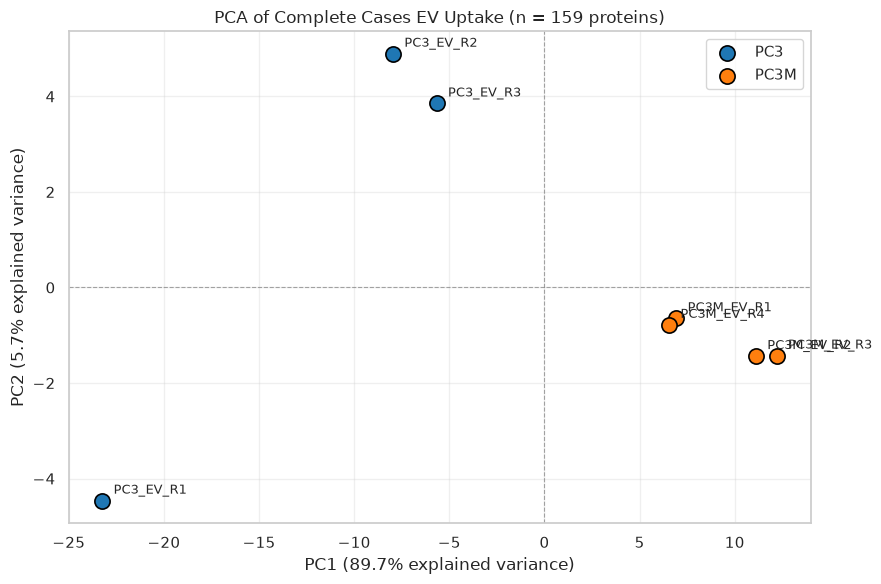

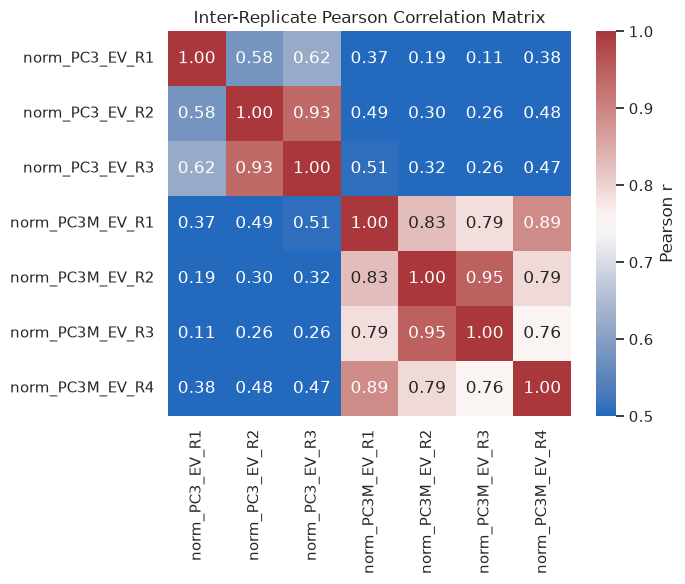

In [54]:
df_pca_input = strict.dropna()
X = df_pca_input.T

sample_names = X.index.tolist()
labels = ["PC3" if "PC3_EV" in s and "PC3M" not in s else "PC3M" for s in sample_names]
colors = {"PC3": "#1f77b4", "PC3M": "#ff7f0e"}

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

# PCA Score Plot
plt.figure(figsize=(9, 6))
for i, sample in enumerate(sample_names):
    group = labels[i]
    plt.scatter(
        coords[i, 0], coords[i, 1], color=colors[group], s=120, edgecolor="black", linewidth=1.2,
        label=group if group not in plt.gca().get_legend_handles_labels()[1] else ""
    )
    plt.annotate(sample.replace("norm_", ""), (coords[i, 0], coords[i, 1]), textcoords="offset points", xytext=(8, 5), fontsize=9)

plt.axhline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.axvline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.title(f"PCA of Complete Cases EV Uptake (n = {len(df_pca_input)} proteins)")
plt.xlabel(f"PC1 ({var_pc1:.1f}% explained variance)")
plt.ylabel(f"PC2 ({var_pc2:.1f}% explained variance)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Pearson Correlation Matrix
plt.figure(figsize=(7, 6))
corr_matrix = df_pca_input.corr(method="pearson")
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag", vmin=0.5, vmax=1.0, cbar_kws={"label": "Pearson r"})
plt.title("Inter-Replicate Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

## 13. Identification of the Global Scale Effect

Examining the PC1 loadings reveals that all feature coefficients are positive ($+0.018$ to $+0.083$). In uncentered PCA, a component with uniform positive signs reflects a **global scale factor**—namely, recipient SAOS-2 cells internalize metastatic PC3M cargo at a systematically higher absolute volume than PC3 cargo.

In [55]:
pc1_loadings = pd.Series(pca.components_[0], index=df_pca_input.index, name="PC1_Loading")
# Retaining all 3 PC3 replicates
mean_pc3 = df_pca_input[["norm_PC3_EV_R1", "norm_PC3_EV_R2", "norm_PC3_EV_R3"]].mean(axis=1)
mean_pc3m = df_pca_input[["norm_PC3M_EV_R1", "norm_PC3M_EV_R2", "norm_PC3M_EV_R3", "norm_PC3M_EV_R4"]].mean(axis=1)
log2_fc_global = (mean_pc3m - mean_pc3).rename("Global_Log2FC_PC3M_vs_PC3")

drivers_df = pd.concat([pc1_loadings, log2_fc_global], axis=1)
print("\tTop 10 PC1 Loadings (Global Scale Dominance):\n")
print(drivers_df.sort_values(by="PC1_Loading", ascending=False).head(10))
print()
print()

print("\tAnti-Top 10 PC1 Loadings:\n")
print(drivers_df.sort_values(by="PC1_Loading", ascending=True).head(10))

	Top 10 PC1 Loadings (Global Scale Dominance):

                           PC1_Loading  Global_Log2FC_PC3M_vs_PC3
Master Protein Accessions                                        
P23229                        0.083585                   3.313838
P21589                        0.083554                   3.535186
P35613                        0.083526                   3.252563
P09543                        0.083452                   3.596595
O00468                        0.083433                   3.660825
P51149                        0.083427                   2.099352
Q9NQ84                        0.083392                   2.657023
P17301                        0.083383                   2.604376
Q06830                        0.083378                   2.200017
Q07020                        0.083366                   2.420473


	Anti-Top 10 PC1 Loadings:

                           PC1_Loading  Global_Log2FC_PC3M_vs_PC3
Master Protein Accessions                                       

## 14. Sample-Median Centering: Isolating Relative Cargo Composition

To isolate specific cargo selectivity from bulk endocytosis rates, we subtract sample medians:

$$\text{Signal}_{\text{rel}, ij} = \text{Signal}_{ij} - \text{Median}_j$$

This transformation resolves specific cargo drivers: proteins internalized preferentially relative to the bulk uptake baseline.

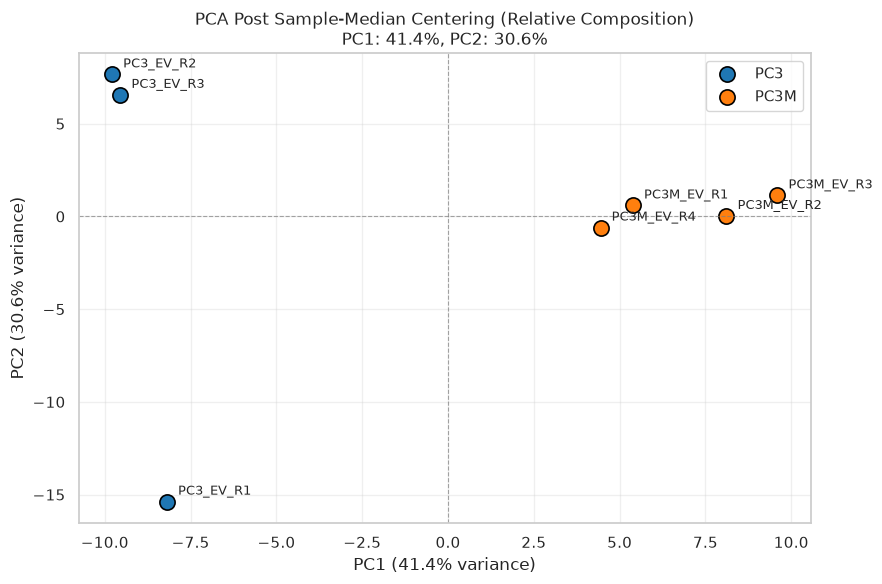

	Top Proteins with Relative Cargo Selectivity (PC3M enriched):

                           PC1_Loading_Centered  Relative_Delta_PC3M_vs_PC3
Master Protein Accessions                                                  
P08572                                 0.122631                    5.819160
P02751                                 0.119917                    3.997408
P21980                                 0.120602                    3.822650
P56199                                 0.108836                    2.470602
P24821                                 0.117487                    2.212438


	Top Proteins with Relative Cargo Selectivity (PC3 enriched):

                           PC1_Loading_Centered  Relative_Delta_PC3M_vs_PC3
Master Protein Accessions                                                  
Q12852                                -0.121389                   -2.101391
P07900                                -0.088742                   -1.984304
Q8TCT9                             

In [56]:
df_centered = df_pca_input.copy()
sample_medians = df_centered.median(axis=0)
df_centered = df_centered.sub(sample_medians, axis=1)

X_cent = df_centered.T
scaler_cent = StandardScaler()
X_cent_scaled = scaler_cent.fit_transform(X_cent)
pca_cent = PCA(n_components=2)
coords_cent = pca_cent.fit_transform(X_cent_scaled)

var_pc1_c = pca_cent.explained_variance_ratio_[0] * 100
var_pc2_c = pca_cent.explained_variance_ratio_[1] * 100

plt.figure(figsize=(9, 6))
for i, sample in enumerate(sample_names):
    group = labels[i]
    plt.scatter(
        coords_cent[i, 0], coords_cent[i, 1], color=colors[group], s=120, edgecolor="black", linewidth=1.2,
        label=group if group not in plt.gca().get_legend_handles_labels()[1] else ""
    )
    plt.annotate(sample.replace("norm_", ""), (coords_cent[i, 0], coords_cent[i, 1]), textcoords="offset points", xytext=(8, 5), fontsize=9)

plt.axhline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.axvline(0, color="grey", linestyle="--", linewidth=0.8, alpha=0.7)
plt.title(f"PCA Post Sample-Median Centering (Relative Composition)\nPC1: {var_pc1_c:.1f}%, PC2: {var_pc2_c:.1f}%")
plt.xlabel(f"PC1 ({var_pc1_c:.1f}% variance)")
plt.ylabel(f"PC2 ({var_pc2_c:.1f}% variance)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Relative Delta calculation across all 3 PC3 replicates
pc1_loadings_cent = pd.Series(pca_cent.components_[0], index=df_centered.index, name="PC1_Loading_Centered")
mean_rel_pc3 = df_centered[["norm_PC3_EV_R1", "norm_PC3_EV_R2", "norm_PC3_EV_R3"]].mean(axis=1)
mean_rel_pc3m = df_centered[["norm_PC3M_EV_R1", "norm_PC3M_EV_R2", "norm_PC3M_EV_R3", "norm_PC3M_EV_R4"]].mean(axis=1)
rel_diff = (mean_rel_pc3m - mean_rel_pc3).rename("Relative_Delta_PC3M_vs_PC3")

cent_drivers = pd.concat([pc1_loadings_cent, rel_diff], axis=1)
print("\tTop Proteins with Relative Cargo Selectivity (PC3M enriched):\n")
print(cent_drivers.sort_values(by="Relative_Delta_PC3M_vs_PC3", ascending=False).head(5))
print()
print()
print("\tTop Proteins with Relative Cargo Selectivity (PC3 enriched):\n")
print(cent_drivers.sort_values(by="Relative_Delta_PC3M_vs_PC3", ascending=True).head(5))

## 15. Univariate Differential Uptake Analysis: Welch's t-Test

We evaluate differential relative uptake between PC3 ($n_1 = 3$: `R1`, `R2`, `R3`) and PC3M ($n_2 = 4$: `R1`, `R2`, `R3`, `R4`).

**Statistical Rationale for Welch's Test:**
1. **Heteroscedasticity**: MS signal variance scales with intensity, violating homoscedasticity.
2. **Unbalanced Groups ($n_1 = 3, n_2 = 4$)**: Student's $t$-test is sensitive to variance discrepancies when group sizes are unequal.
3. **Welch–Satterthwaite Adjustment**: Degrees of freedom are estimated adaptively from sample variances:

$$\nu \approx \frac{\left(\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}\right)^2}{\frac{(s_1^2 / n_1)^2}{n_1 - 1} + \frac{(s_2^2 / n_2)^2}{n_2 - 1}}$$

Multiple testing correction is applied using the Benjamini–Hochberg False Discovery Rate (FDR < 0.10, $log_2({FC}) \ge 1.0$).

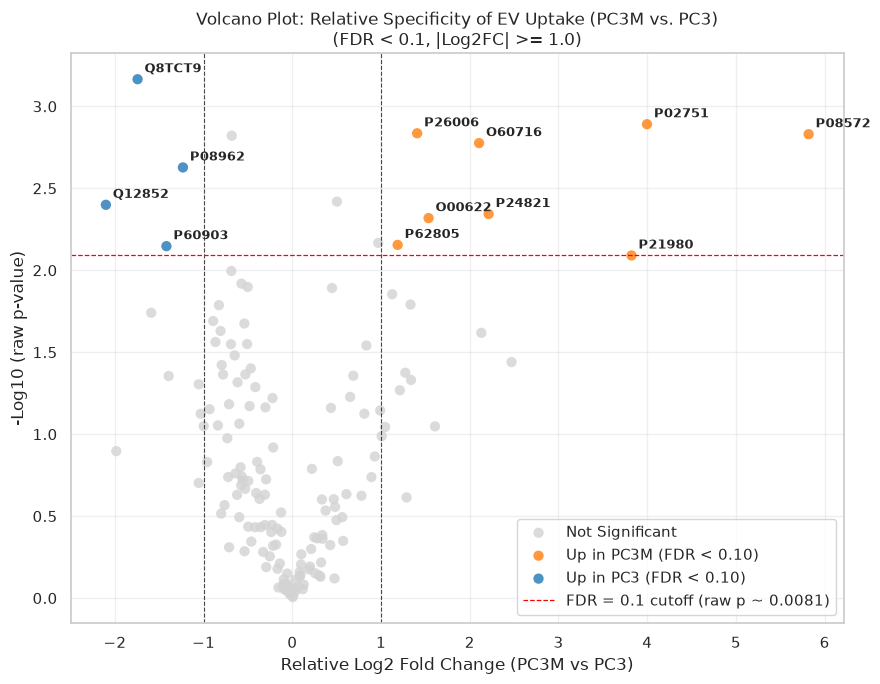

Proteins meeting FDR < 0.1 and |Log2FC| >= 1.0: 12

             Log2FC   p_value   q_value             Significance
Accession                                                       
O60716     2.104834  0.001675  0.044389  Up in PC3M (FDR < 0.10)
P02751     3.997408  0.001285  0.044389  Up in PC3M (FDR < 0.10)
P08572     5.819160  0.001479  0.044389  Up in PC3M (FDR < 0.10)
P26006     1.406785  0.001460  0.044389  Up in PC3M (FDR < 0.10)
Q8TCT9    -1.744235  0.000683  0.044389   Up in PC3 (FDR < 0.10)
P08962    -1.233099  0.002358  0.053565   Up in PC3 (FDR < 0.10)
P24821     2.212438  0.004535  0.069467  Up in PC3M (FDR < 0.10)
O00622     1.535682  0.004806  0.069467  Up in PC3M (FDR < 0.10)
Q12852    -2.101391  0.003987  0.069467   Up in PC3 (FDR < 0.10)
P62805     1.187132  0.007002  0.080947  Up in PC3M (FDR < 0.10)
P60903    -1.418956  0.007127  0.080947   Up in PC3 (FDR < 0.10)
P21980     3.822650  0.008123  0.086109  Up in PC3M (FDR < 0.10)


In [57]:
pc3_cols = ["norm_PC3_EV_R1", "norm_PC3_EV_R2", "norm_PC3_EV_R3"]
pc3m_cols = ["norm_PC3M_EV_R1", "norm_PC3M_EV_R2", "norm_PC3M_EV_R3", "norm_PC3M_EV_R4"]

p_values = []
log2_fc_list = []

for protein in df_centered.index:
    vals_pc3 = df_centered.loc[protein, pc3_cols].values
    vals_pc3m = df_centered.loc[protein, pc3m_cols].values

    fc = np.mean(vals_pc3m) - np.mean(vals_pc3)
    log2_fc_list.append(fc)

    stat, p_val = stats.ttest_ind(vals_pc3m, vals_pc3, equal_var=False)
    p_values.append(p_val)

volcano_df = pd.DataFrame({
    "Accession": df_centered.index,
    "Log2FC": log2_fc_list,
    "p_value": p_values,
    "neg_log10_p": -np.log10(p_values),
}).set_index("Accession")

fdr_threshold = 0.10
fc_threshold = 1.0

reject, q_values, _, _ = multipletests(volcano_df["p_value"], alpha=fdr_threshold, method="fdr_bh")
volcano_df["q_value"] = q_values
volcano_df["FDR_Significant"] = reject
volcano_df["neg_log10_q"] = -np.log10(volcano_df["q_value"])

volcano_df["Significance"] = "Not Significant"
volcano_df.loc[(volcano_df["FDR_Significant"]) & (volcano_df["Log2FC"] >= fc_threshold), "Significance"] = "Up in PC3M (FDR < 0.10)"
volcano_df.loc[(volcano_df["FDR_Significant"]) & (volcano_df["Log2FC"] <= -fc_threshold), "Significance"] = "Up in PC3 (FDR < 0.10)"

# Volcano plot
plt.figure(figsize=(9, 7))
colors_volcano = {"Not Significant": "lightgrey", "Up in PC3M (FDR < 0.10)": "#ff7f0e", "Up in PC3 (FDR < 0.10)": "#1f77b4"}

for status, color in colors_volcano.items():
    subset = volcano_df[volcano_df["Significance"] == status]
    plt.scatter(subset["Log2FC"], subset["neg_log10_p"], c=color, label=status, alpha=0.8, edgecolors="none", s=55)

plt.axvline(fc_threshold, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
plt.axvline(-fc_threshold, color="black", linestyle="--", linewidth=0.8, alpha=0.7)

sig_hits = volcano_df[volcano_df["FDR_Significant"]]
if not sig_hits.empty:
    p_cutoff_nominal = sig_hits["p_value"].max()
    plt.axhline(-np.log10(p_cutoff_nominal), color="red", linestyle="--", linewidth=0.9, label=f"FDR = {fdr_threshold} cutoff (raw p ~ {p_cutoff_nominal:.4f})")

top_annot = volcano_df[volcano_df["Significance"] != "Not Significant"].sort_values(by="p_value", ascending=True)
for acc, row in top_annot.iterrows():
    plt.annotate(acc, (row["Log2FC"], row["neg_log10_p"]), textcoords="offset points", xytext=(5, 5), fontsize=9, fontweight="bold")

plt.title(f"Volcano Plot: Relative Specificity of EV Uptake (PC3M vs. PC3)\n(FDR < {fdr_threshold}, |Log2FC| >= {fc_threshold})")
plt.xlabel("Relative Log2 Fold Change (PC3M vs PC3)")
plt.ylabel("-Log10 (raw p-value)")
plt.legend(frameon=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fdr_hits = volcano_df[volcano_df["Significance"] != "Not Significant"]
print(f"Proteins meeting FDR < {fdr_threshold} and |Log2FC| >= {fc_threshold}: {len(fdr_hits)}\n")
print(fdr_hits[["Log2FC", "p_value", "q_value", "Significance"]].sort_values(by="q_value"))

## 16. Supervised Machine Learning: Random Forest Feature Importance

To complement hypothesis testing with a non-parametric multivariate model, we train a Random Forest classifier consisting of decision stumps (`max_depth=1`, 15,000 trees). Generalization accuracy is audited via Leave-One-Out Cross-Validation (LOOCV).

Leave-One-Out Cross-Validation Accuracy: 85.7%


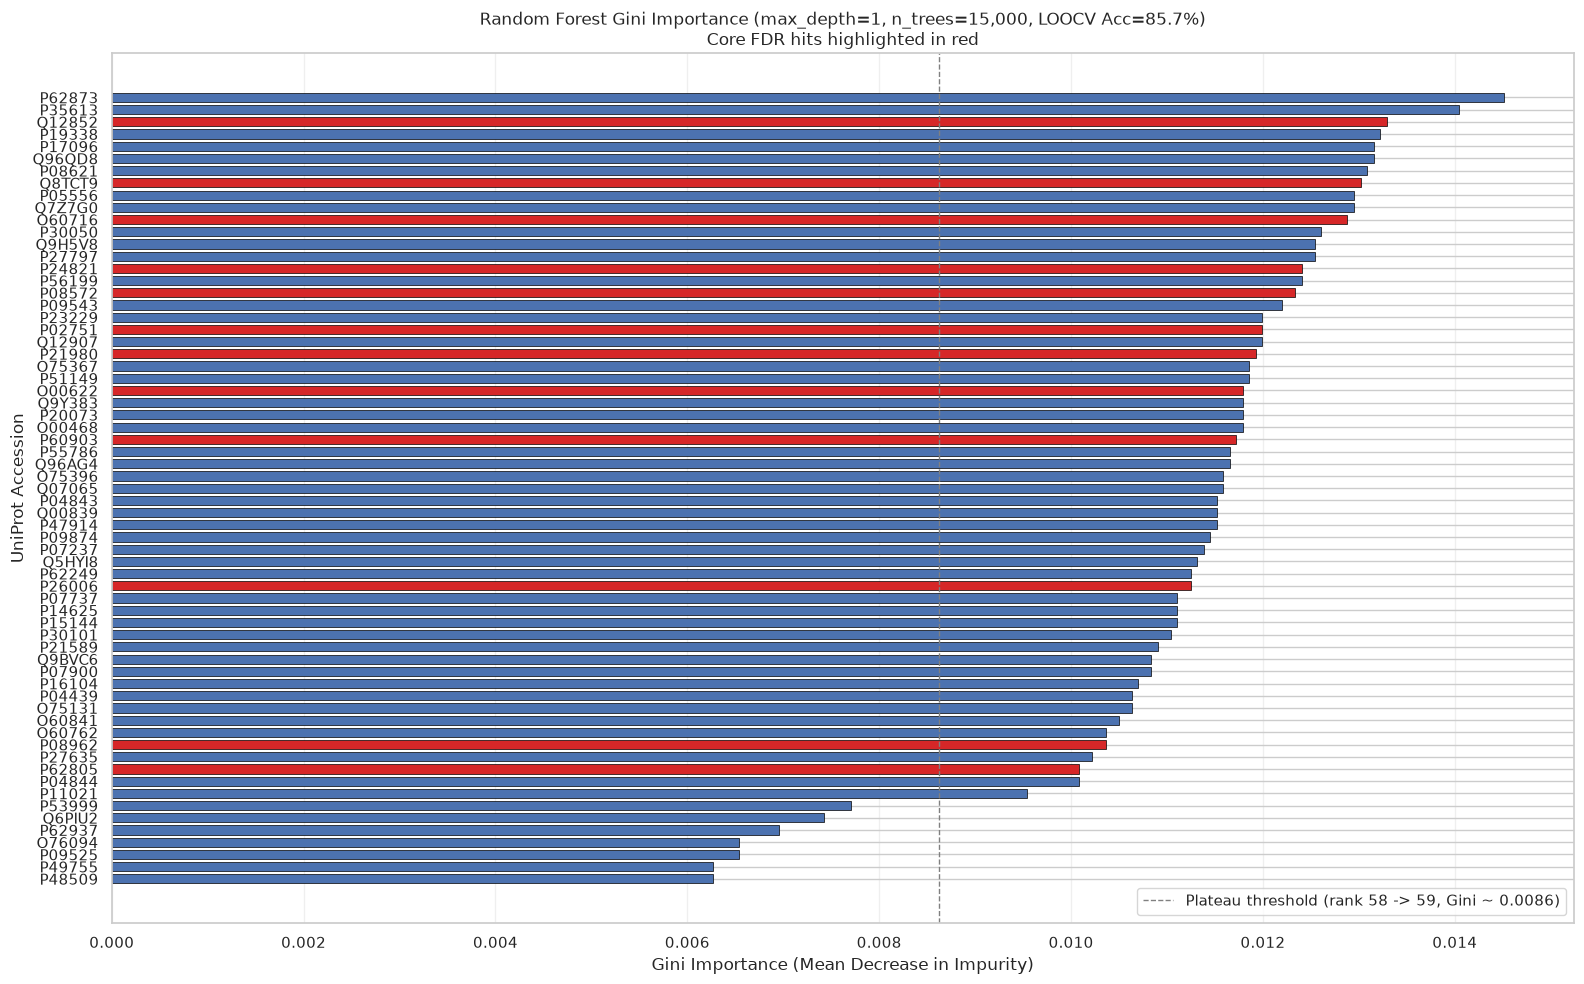

In [58]:
X_all = df_centered.T
sample_labels = [0 if "PC3_EV" in s and "PC3M" not in s else 1 for s in X_all.index]
y_all = np.array(sample_labels)

# LOOCV Validation
loo = LeaveOneOut()
y_true, y_pred = [], []

for train_idx, test_idx in loo.split(X_all):
    X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
    y_train, y_test = y_all[train_idx], y_all[test_idx]

    rf_cv = RandomForestClassifier(n_estimators=500, max_depth=1, random_state=42, max_features="sqrt", n_jobs=-1)
    rf_cv.fit(X_train, y_train)
    pred = rf_cv.predict(X_test)
    y_true.append(y_test[0])
    y_pred.append(pred[0])

loocv_acc = accuracy_score(y_true, y_pred)
print(f"Leave-One-Out Cross-Validation Accuracy: {loocv_acc * 100:.1f}%")

# Full Ensemble for Feature Ranking
rf_final = RandomForestClassifier(n_estimators=15000, max_depth=1, random_state=42, max_features="sqrt", n_jobs=-1)
rf_final.fit(X_all, y_all)

importances = pd.Series(rf_final.feature_importances_, index=X_all.columns, name="Gini_Importance").sort_values(ascending=False)
fdr_set = set(fdr_hits.index)

top_n = 65
plot_series = importances.head(top_n).sort_values(ascending=True)
bar_colors = ["#d62728" if acc in fdr_set else "#4c72b0" for acc in plot_series.index]

plt.figure(figsize=(16, 10))
plt.barh(plot_series.index, plot_series.values, color=bar_colors, edgecolor="black", linewidth=0.5, height=0.75)
cutoff_val = (importances.iloc[57] + importances.iloc[58]) / 2
plt.axvline(cutoff_val, color="gray", linestyle="--", linewidth=1.0, label=f"Plateau threshold (rank 58 -> 59, Gini ~ {cutoff_val:.4f})")

plt.title(f"Random Forest Gini Importance (max_depth=1, n_trees=15,000, LOOCV Acc={loocv_acc*100:.1f}%)\nCore FDR hits highlighted in red")
plt.xlabel("Gini Importance (Mean Decrease in Impurity)")
plt.ylabel("UniProt Accession")
plt.legend(frameon=True, loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
print("Sample-level LOOCV classification results:")
for name, true_y, pred_y in zip(X_all.index, y_true, y_pred):
    status = "Concordant" if true_y == pred_y else "Discordant"
    print(f"{name:<20} | Ground Truth: {true_y} | Predicted: {pred_y} | {status}")

Sample-level LOOCV classification results:
norm_PC3_EV_R1       | Ground Truth: 0 | Predicted: 1 | Discordant
norm_PC3_EV_R2       | Ground Truth: 0 | Predicted: 0 | Concordant
norm_PC3_EV_R3       | Ground Truth: 0 | Predicted: 0 | Concordant
norm_PC3M_EV_R1      | Ground Truth: 1 | Predicted: 1 | Concordant
norm_PC3M_EV_R2      | Ground Truth: 1 | Predicted: 1 | Concordant
norm_PC3M_EV_R3      | Ground Truth: 1 | Predicted: 1 | Concordant
norm_PC3M_EV_R4      | Ground Truth: 1 | Predicted: 1 | Concordant


## 17. Hierarchical Clustering

Lets take a look how well those statisticly important proteins separate conditions:

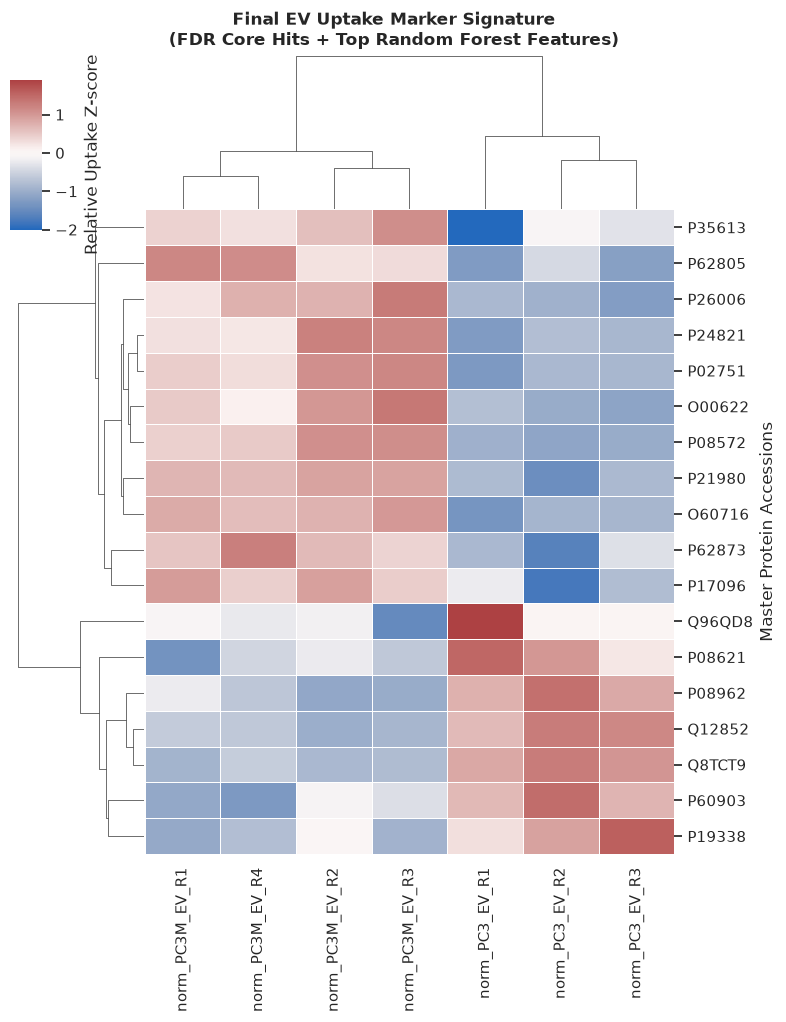

In [60]:
key_markers = list(dict.fromkeys(list(fdr_set) + [acc for acc in importances.index if acc not in fdr_set][:6]))
heatmap_data = df_centered.loc[key_markers]

g = sns.clustermap(
    heatmap_data,
    cmap="vlag",
    center=0,
    z_score=0,
    col_cluster=True,
    row_cluster=True,
    figsize=(8, 10),
    dendrogram_ratio=(0.2, 0.2),
    cbar_pos=(0.02, 0.8, 0.04, 0.15),
    cbar_kws={"label": "Relative Uptake Z-score"},
    linewidths=0.5,
    linecolor="white",
    method="average",
)
g.figure.suptitle("Final EV Uptake Marker Signature\n(FDR Core Hits + Top Random Forest Features)", y=1.02, fontsize=12, fontweight="bold")
plt.show()

### Post-Clustering Validation of Replicate Concordance

The hierarchical clustering dendrogram demonstrates that **`PC3_EV_R1` clusters strictly within the PC3 clade alongside `PC3_EV_R2` and `PC3_EV_R3`**, cleanly separated from the four PC3M replicates. 

This confirms our initial methodological stance: despite its wider variance and lower pairwise correlation, `PC3_EV_R1` preserves canonical PC3 uptake biology. Retaining it prevented artificial variance underestimation and ensured that our statistical inferences reflect genuine biological variation rather than curated sample selection.

## 18. Orthogonal Projection: Supervised Ranking vs. Univariate Volcano Significance

To examine the agreement between univariate hypothesis testing and multivariate machine learning, we project Random Forest importance ranks onto the Volcano plot. A continuous color and point-size gradient highlights proteins within the top-58 importance plateau that fall just below stringent FDR thresholds due to degrees-of-freedom penalties.

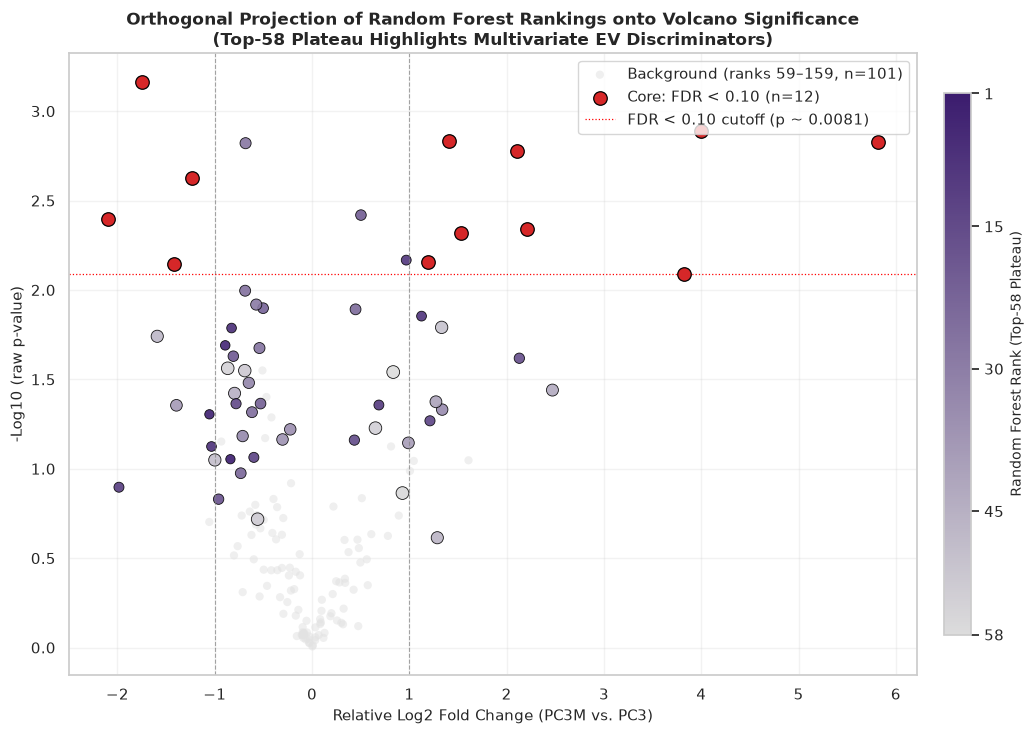

In [61]:
rank_series = pd.Series(range(1, len(importances) + 1), index=importances.index, name="RF_Rank")
volcano_df["RF_Rank"] = volcano_df.index.map(rank_series)
volcano_df["Is_FDR_Core"] = volcano_df.index.isin(list(fdr_set))

custom_cmap = LinearSegmentedColormap.from_list("rf_gradient", ["#dcdcdc", "#3b1c6e"], N=256).reversed()

# Plotting Layers
bg_mask = (volcano_df["RF_Rank"] > 58) & (~volcano_df["Is_FDR_Core"])
df_bg = volcano_df[bg_mask]

dh_mask = (volcano_df["RF_Rank"] <= 58) & (~volcano_df["Is_FDR_Core"])
df_dh = volcano_df[dh_mask].copy()
df_core = volcano_df[volcano_df["Is_FDR_Core"]]

df_dh["Intensity"] = (58 - df_dh["RF_Rank"]) / (58 - 1)
dh_colors = custom_cmap(df_dh["Intensity"])
dh_sizes = 45 + 40 * df_dh["Intensity"]

fig, ax = plt.subplots(figsize=(10.5, 7.5))

# 1. Background Noise
ax.scatter(df_bg["Log2FC"], df_bg["neg_log10_p"], c="#e2e2e2", s=35, alpha=0.55, edgecolors="none", label=f"Background (ranks 59–159, n={len(df_bg)})", zorder=1)

# 2. Random Forest Plateau Features
ax.scatter(df_dh["Log2FC"], df_dh["neg_log10_p"], c=dh_colors, s=dh_sizes, alpha=0.9, edgecolors="black", linewidths=0.6, zorder=2)

# 3. Core FDR Hits
ax.scatter(df_core["Log2FC"], df_core["neg_log10_p"], c="#d62728", s=95, alpha=1.0, edgecolors="black", linewidths=0.9, label=f"Core: FDR < 0.10 (n={len(df_core)})", zorder=3)

# Thresholds
ax.axvline(1.0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax.axvline(-1.0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
if not df_core.empty:
    p_cutoff_nominal = df_core["p_value"].max()
    ax.axhline(-np.log10(p_cutoff_nominal), color="red", linestyle=":", linewidth=0.9, label=f"FDR < 0.10 cutoff (p ~ {p_cutoff_nominal:.4f})")

# Gradient Colorbar
sm = plt.cm.ScalarMappable(cmap=custom_cmap, norm=Normalize(vmin=1, vmax=58))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.03)
cbar.set_label("Random Forest Rank (Top-58 Plateau)", fontsize=10)
cbar.set_ticks([1, 15, 30, 45, 58])
cbar.ax.invert_yaxis()

ax.set_title("Orthogonal Projection of Random Forest Rankings onto Volcano Significance\n(Top-58 Plateau Highlights Multivariate EV Discriminators)", fontsize=12, fontweight="bold")
ax.set_xlabel("Relative Log2 Fold Change (PC3M vs. PC3)", fontsize=11)
ax.set_ylabel("-Log10 (raw p-value)", fontsize=11)
ax.legend(frameon=True, loc="upper right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()